# Automated Web Security Scanner
**Author:** Adi
**Topic:** Python script to audit websites for missing secure headers, CORS misconfigurations and weak cookie flags.

The notebook scans a list of targets, scores each one out of 100, saves the findings to a CSV file and draws charts.
By default it scans **three local demo servers** (weak, mixed, hardened) so it runs fully offline and legally.

> Only scan websites you own or have written permission to test.

In [1]:
import json
import threading
from datetime import datetime
from http.server import BaseHTTPRequestHandler, HTTPServer

import matplotlib.pyplot as plt
import pandas as pd
import requests

print("Libraries loaded")

Libraries loaded


## 1. Configuration
Each security header has a severity weight. The weight is subtracted from the 100-point score when the header is missing.

In [2]:
SECURITY_HEADERS = {
    "Strict-Transport-Security": {"weight": 15, "fix": "Add: Strict-Transport-Security: max-age=31536000; includeSubDomains"},
    "Content-Security-Policy":   {"weight": 20, "fix": "Add a Content-Security-Policy, e.g. default-src 'self'"},
    "X-Frame-Options":           {"weight": 10, "fix": "Add: X-Frame-Options: DENY (or SAMEORIGIN)"},
    "X-Content-Type-Options":    {"weight": 10, "fix": "Add: X-Content-Type-Options: nosniff"},
    "Referrer-Policy":           {"weight": 5,  "fix": "Add: Referrer-Policy: strict-origin-when-cross-origin"},
    "Permissions-Policy":        {"weight": 5,  "fix": "Add a Permissions-Policy to limit camera, mic, geolocation"},
}

LEAKY_HEADERS = ["Server", "X-Powered-By"]   # reveal technology and version
EVIL_ORIGIN = "https://evil.example"
TIMEOUT = 5  # seconds per request

SEVERITY_ORDER = ["Critical", "High", "Medium", "Low", "Info"]

## 2. Demo servers (offline test targets)
Three tiny HTTP servers with different security levels, so the scanner can be tested without touching real websites.

In [3]:
class BaseDemoHandler(BaseHTTPRequestHandler):
    """Skips Python's automatic Server header so each demo controls its own headers."""
    def send_response(self, code, message=None):
        self.send_response_only(code, message)
        self.send_header("Date", self.date_time_string())

    def log_message(self, *args):
        pass


class WeakHandler(BaseDemoHandler):
    """No security headers, leaks versions, reflects any Origin with credentials."""
    def do_GET(self):
        origin = self.headers.get("Origin")
        self.send_response(200)
        self.send_header("Content-Type", "text/html")
        self.send_header("Server", "Apache/2.2.8 (Ubuntu)")
        self.send_header("X-Powered-By", "PHP/5.2.4")
        if origin:
            self.send_header("Access-Control-Allow-Origin", origin)
            self.send_header("Access-Control-Allow-Credentials", "true")
        self.send_header("Set-Cookie", "session=abc123; Path=/")
        self.end_headers()
        self.wfile.write(b"weak site")


class MixedHandler(BaseDemoHandler):
    """Some headers present, wildcard CORS, partly secure cookie."""
    def do_GET(self):
        self.send_response(200)
        self.send_header("Content-Type", "text/html")
        self.send_header("X-Frame-Options", "SAMEORIGIN")
        self.send_header("X-Content-Type-Options", "nosniff")
        self.send_header("Access-Control-Allow-Origin", "*")
        self.send_header("Set-Cookie", "session=abc123; Path=/; HttpOnly")
        self.end_headers()
        self.wfile.write(b"mixed site")


class StrongHandler(BaseDemoHandler):
    """All recommended headers, no CORS, hardened cookie."""
    def do_GET(self):
        self.send_response(200)
        self.send_header("Content-Type", "text/html")
        self.send_header("Strict-Transport-Security", "max-age=31536000; includeSubDomains")
        self.send_header("Content-Security-Policy", "default-src 'self'")
        self.send_header("X-Frame-Options", "DENY")
        self.send_header("X-Content-Type-Options", "nosniff")
        self.send_header("Referrer-Policy", "strict-origin-when-cross-origin")
        self.send_header("Permissions-Policy", "camera=(), microphone=(), geolocation=()")
        self.send_header("Set-Cookie", "session=abc123; Path=/; Secure; HttpOnly; SameSite=Strict")
        self.end_headers()
        self.wfile.write(b"strong site")


def start_server(handler, port):
    server = HTTPServer(("127.0.0.1", port), handler)
    threading.Thread(target=server.serve_forever, daemon=True).start()
    return server


DEMO_SERVERS = [
    start_server(WeakHandler, 8001),
    start_server(MixedHandler, 8002),
    start_server(StrongHandler, 8003),
]
print("Demo servers running on ports 8001, 8002, 8003")

Demo servers running on ports 8001, 8002, 8003


## 3. Scanner functions
Three checks: security headers, CORS policy, and cookie flags. Every problem becomes one finding with a severity and a recommended fix.

In [4]:
def make_finding(url, check, severity, issue, fix):
    return {"url": url, "check": check, "severity": severity, "issue": issue, "fix": fix}


def check_headers(url, response):
    findings = []
    for header, info in SECURITY_HEADERS.items():
        if header not in response.headers:
            severity = "High" if info["weight"] >= 15 else "Medium" if info["weight"] >= 10 else "Low"
            findings.append(make_finding(url, "Security Header", severity, f"Missing {header}", info["fix"]))
    for header in LEAKY_HEADERS:
        if header in response.headers:
            findings.append(make_finding(
                url, "Information Leak", "Low",
                f"{header} reveals technology: {response.headers[header]}",
                f"Remove or genericize the {header} header"))
    return findings


def check_cors(url):
    findings = []
    try:
        resp = requests.get(url, headers={"Origin": EVIL_ORIGIN}, timeout=TIMEOUT)
    except requests.RequestException:
        return findings
    allow_origin = resp.headers.get("Access-Control-Allow-Origin")
    allow_creds = resp.headers.get("Access-Control-Allow-Credentials", "").lower() == "true"
    if allow_origin == EVIL_ORIGIN and allow_creds:
        findings.append(make_finding(url, "CORS", "Critical",
            "Reflects any Origin and allows credentials", "Use a strict allow-list of trusted origins"))
    elif allow_origin == EVIL_ORIGIN:
        findings.append(make_finding(url, "CORS", "High",
            "Reflects arbitrary Origin", "Use a strict allow-list of trusted origins"))
    elif allow_origin == "*":
        findings.append(make_finding(url, "CORS", "Medium",
            "Wildcard Access-Control-Allow-Origin: *", "Restrict to specific trusted origins"))
    return findings


def check_cookies(url, response):
    findings = []
    raw_cookies = response.raw.headers.getlist("Set-Cookie") if hasattr(response.raw.headers, "getlist") else []
    for cookie in raw_cookies:
        name = cookie.split("=")[0]
        lowered = cookie.lower()
        for flag, severity in (("secure", "Medium"), ("httponly", "Medium"), ("samesite", "Low")):
            if flag not in lowered:
                findings.append(make_finding(url, "Cookie", severity,
                    f"Cookie '{name}' missing {flag} flag", f"Add the {flag} attribute to the cookie"))
    return findings


def calculate_score(findings):
    penalty = {"Critical": 25, "High": 15, "Medium": 8, "Low": 3, "Info": 0}
    return max(0, 100 - sum(penalty[f["severity"]] for f in findings))


def grade(score):
    return "A" if score >= 90 else "B" if score >= 75 else "C" if score >= 60 else "D" if score >= 40 else "F"


def scan_site(url):
    """Run all checks on one URL. Returns (findings list, score)."""
    try:
        response = requests.get(url, timeout=TIMEOUT, stream=True)
    except requests.RequestException as err:
        return [make_finding(url, "Connection", "Info", f"Could not connect: {err.__class__.__name__}", "Check URL")], None
    findings = check_headers(url, response) + check_cors(url) + check_cookies(url, response)
    return findings, calculate_score(findings)

## 4. Run the scan
`TARGETS` holds the demo servers. To scan real websites, add **your own** URLs to `TARGETS`.

In [5]:
TARGETS = [
    "http://127.0.0.1:8001",   # weak demo
    "http://127.0.0.1:8002",   # mixed demo
    "http://127.0.0.1:8003",   # hardened demo
]
LABELS = {"http://127.0.0.1:8001": "Weak demo", "http://127.0.0.1:8002": "Mixed demo", "http://127.0.0.1:8003": "Strong demo"}

all_findings, summary_rows = [], []
for target in TARGETS:
    findings, score = scan_site(target)
    all_findings.extend(findings)
    summary_rows.append({
        "site": LABELS.get(target, target),
        "url": target,
        "score": score,
        "grade": grade(score) if score is not None else "N/A",
        "total_findings": len(findings),
    })

findings_df = pd.DataFrame(all_findings)
summary_df = pd.DataFrame(summary_rows)
summary_df

,site,url,score,grade,total_findings
0,Weak demo,http://127.0.0.1:8001,0,F,12
1,Mixed demo,http://127.0.0.1:8002,45,D,7
2,Strong demo,http://127.0.0.1:8003,100,A,0


In [6]:
# Full findings table, most severe first
findings_df["severity"] = pd.Categorical(findings_df["severity"], categories=SEVERITY_ORDER, ordered=True)
findings_df = findings_df.sort_values(["url", "severity"]).reset_index(drop=True)
findings_df

,url,check,severity,issue,fix
0,http://127.0.0.1:8001,CORS,Critical,Reflects any Origin and allows credentials,Use a strict allow-list of trusted origins
1,http://127.0.0.1:8001,Security Header,High,Missing Strict-Transport-Security,Add: Strict-Transport-Security: max-age=315360...
2,http://127.0.0.1:8001,Security Header,High,Missing Content-Security-Policy,"Add a Content-Security-Policy, e.g. default-sr..."
3,http://127.0.0.1:8001,Security Header,Medium,Missing X-Frame-Options,Add: X-Frame-Options: DENY (or SAMEORIGIN)
4,http://127.0.0.1:8001,Security Header,Medium,Missing X-Content-Type-Options,Add: X-Content-Type-Options: nosniff
5,http://127.0.0.1:8001,Cookie,Medium,Cookie 'session' missing secure flag,Add the secure attribute to the cookie
6,http://127.0.0.1:8001,Cookie,Medium,Cookie 'session' missing httponly flag,Add the httponly attribute to the cookie
7,http://127.0.0.1:8001,Security Header,Low,Missing Referrer-Policy,Add: Referrer-Policy: strict-origin-when-cross...
8,http://127.0.0.1:8001,Security Header,Low,Missing Permissions-Policy,"Add a Permissions-Policy to limit camera, mic,..."
9,http://127.0.0.1:8001,Information Leak,Low,Server reveals technology: Apache/2.2.8 (Ubuntu),Remove or genericize the Server header


## 5. Save results

In [7]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
findings_df.to_csv("scan_findings.csv", index=False)
summary_df.to_csv("scan_summary.csv", index=False)
with open("scan_report.json", "w") as f:
    json.dump({"scanned_at": timestamp, "summary": summary_rows}, f, indent=2)
print("Saved: scan_findings.csv, scan_summary.csv, scan_report.json")

Saved: scan_findings.csv, scan_summary.csv, scan_report.json


## 6. Visualisation

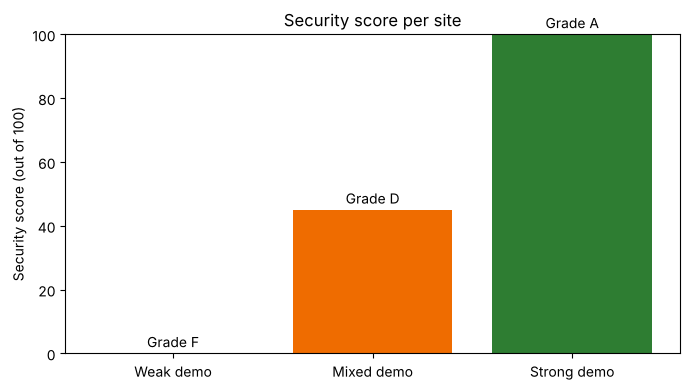

In [8]:
# Chart 1: security score per site
colors = {"A": "#2e7d32", "B": "#7cb342", "C": "#f9a825", "D": "#ef6c00", "F": "#c62828", "N/A": "#9e9e9e"}
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(summary_df["site"], summary_df["score"].fillna(0),
              color=[colors[g] for g in summary_df["grade"]])
ax.set_ylim(0, 100)
ax.set_ylabel("Security score (out of 100)")
ax.set_title("Security score per site")
for bar, g in zip(bars, summary_df["grade"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2, f"Grade {g}", ha="center")
plt.tight_layout()
plt.savefig("chart_scores.png", dpi=150)
plt.show()

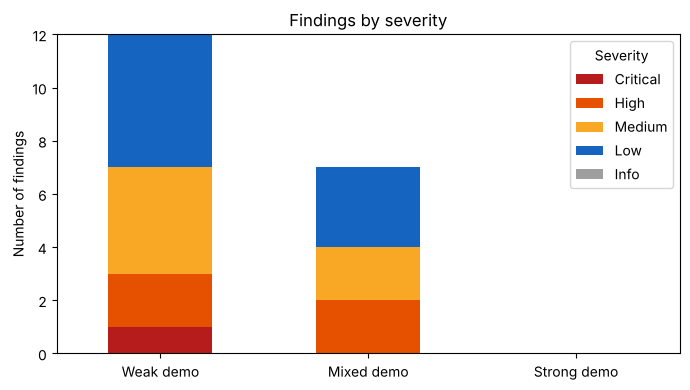

In [9]:
# Chart 2: findings by severity for each site
pivot = (findings_df.groupby(["url", "severity"], observed=False).size()
         .unstack(fill_value=0).reindex(columns=SEVERITY_ORDER, fill_value=0))
pivot = pivot.reindex(TARGETS, fill_value=0)   # keep sites that have zero findings
pivot.index = [LABELS.get(u, u) for u in pivot.index]
sev_colors = ["#b71c1c", "#e65100", "#f9a825", "#1565c0", "#9e9e9e"]
ax = pivot.plot(kind="bar", stacked=True, figsize=(7, 4), color=sev_colors)
ax.set_ylabel("Number of findings")
ax.set_title("Findings by severity")
ax.legend(title="Severity", loc="upper right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("chart_severity.png", dpi=150)
plt.show()

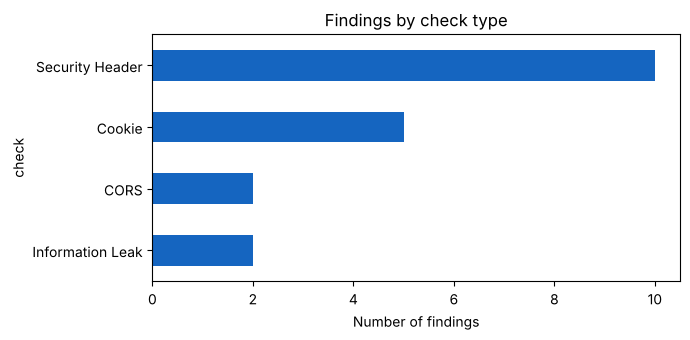

In [10]:
# Chart 3: which checks fail most often
by_check = findings_df["check"].value_counts()
ax = by_check.plot(kind="barh", figsize=(7, 3.5), color="#1565c0")
ax.set_xlabel("Number of findings")
ax.set_title("Findings by check type")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("chart_checks.png", dpi=150)
plt.show()

## 7. Conclusion
- The **weak** demo site gets an F: no headers, leaked server versions, a critical CORS flaw and unprotected cookies.
- The **mixed** demo site shows a partly configured site: a few headers present, but wildcard CORS and missing CSP/HSTS.
- The **strong** demo site scores 100 with all recommended headers, no CORS exposure and a hardened cookie.

**Takeaway:** most web weaknesses are simple configuration gaps. A small automated script can find them in seconds and list the exact fix for each.

In [11]:
for server in DEMO_SERVERS:
    server.shutdown()
print("Demo servers stopped")

Demo servers stopped
